# F4 · Incertidumbre de los indicadores y evolución temporal

**Proyecto MCDI500 · Grupo 7 · Aporte de Javier**

Este notebook complementa `F4_Comunicacion_Resultados.ipynb` con dos componentes pedidos en la retroalimentación de F3:

| Componente | Sugerencia del profesor | Código |
|---|---|---|
| **A. Evolución temporal** | Punto 2: mapa de calor comuna × mes y los indicadores con y sin el apagón del 25-02-2025 | `src/temporal.py` |
| **B. Incertidumbre** | Punto 1 (prioridad alta): intervalo exacto de Poisson para las tasas, bootstrap para las medianas y marca de baja precisión bajo 30 intervalos | `src/incertidumbre.py` |

Las funciones viven en `src/` y tienen pruebas en `tests/test_aportes_f4.py`. El notebook solo las importa, ejecuta y comunica. **No modifica ningún archivo existente:** escribe únicamente sus propias figuras (`F4/figuras/F4_Figura_505` a `507`) y tablas (`F4/resultados/F4_Tabla_405` a `408`).

**Cómo leer este notebook.** Un *informe* es un documento de falla publicado por el CEN. Un *vínculo* (o asociación) une un informe con una comuna: un informe que nombra tres comunas genera tres vínculos. Un *intervalo documental* es el tiempo entre la perturbación y el término registrados en un informe finalizado. Un *intervalo de confianza* es el rango de valores compatibles con los datos: si los rangos de dos comunas se superponen, los datos no permiten afirmar que una tenga más que la otra.

## 1. Carga y verificación de los datos

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.incertidumbre import (duracion_con_intervalo, frecuencia_con_intervalo,
                               pares_no_distinguibles, se_superponen,
                               UMBRAL_BAJA_PRECISION)
from src.temporal import (FECHA_APAGON, contar_informes_mensuales,
                          graficar_mapa_calor, peso_de_un_dia)

DIR_FIGURAS = RAIZ / "F4" / "figuras"
DIR_RESULTADOS = RAIZ / "F4" / "resultados"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

FUENTE = ("Fuente: elaboración propia con informes de falla del Coordinador Eléctrico "
          "Nacional (CEN, ene-2024 a sep-2026) y población del Censo 2024 (INE).")

asociaciones = pd.read_csv(
    RAIZ / "data" / "processed" / "f2" / "04_cen_fallas_comunas_integrado.csv",
    low_memory=False, dtype={"codigo_comuna": str}
)
panel = pd.read_csv(
    RAIZ / "F3" / "resultados" / "F3_701_Panel_Integrado_Comunal.csv",
    dtype={"codigo_comuna": str}
)

assert len(asociaciones) == 1915, "Se esperaban 1.915 vínculos informe-comuna."
assert asociaciones["id_falla"].nunique() == 1834, "Se esperaban 1.834 informes."
assert len(panel) == 15, "El panel de F3 debe tener 15 comunas."

no_anulados = asociaciones["estado_normalizado"].str.upper().ne("ANULADO")
print(f"Vínculos: {len(asociaciones):,} · no anulados: {no_anulados.sum():,} · comunas: {len(panel)}")

Vínculos: 1,915 · no anulados: 1,784 · comunas: 15


## 2. Componente A · Evolución mensual por comuna

Se cuentan los **informes no anulados distintos** de cada comuna en cada uno de los 33 meses, la misma unidad del indicador de frecuencia de F3. Las comunas se ordenan según la frecuencia normalizada de la Figura 5.1, para que ambas figuras se lean en el mismo orden.

In [2]:
orden_frecuencia = (
    panel.sort_values("frecuencia_100k_hab_anio", ascending=False)["comuna_oficial"].tolist()
)
matriz = contar_informes_mensuales(asociaciones, orden_comunas=orden_frecuencia)

assert matriz.shape == (15, 33)
assert int(matriz.to_numpy().sum()) == int(panel["informes_no_anulados"].sum()), \
    "La matriz no suma los informes no anulados del panel de F3."

total_mes = matriz.sum()
mes_pico = total_mes.idxmax()
# La suma por columna cuenta vínculos informe-comuna: un informe que nombra
# tres comunas aparece en tres filas.
print(f"Mes con más vínculos: {mes_pico} ({total_mes.max()} vínculos, "
      f"{total_mes.max() / total_mes.drop(mes_pico).median():.1f} veces la mediana del resto)")
print(f"Mediana mensual de los demás meses: {total_mes.drop(mes_pico).median():.0f} vínculos")
fechas = pd.to_datetime(asociaciones.loc[no_anulados, "fecha_perturbacion_dt"], format="mixed")
informes_mes_pico = asociaciones.loc[no_anulados].loc[fechas.dt.to_period("M") == mes_pico, "id_falla"].nunique()
print(f"Informes distintos en {mes_pico}: {informes_mes_pico}")

Mes con más vínculos: 2025-02 (283 vínculos, 6.6 veces la mediana del resto)
Mediana mensual de los demás meses: 43 vínculos
Informes distintos en 2025-02: 264


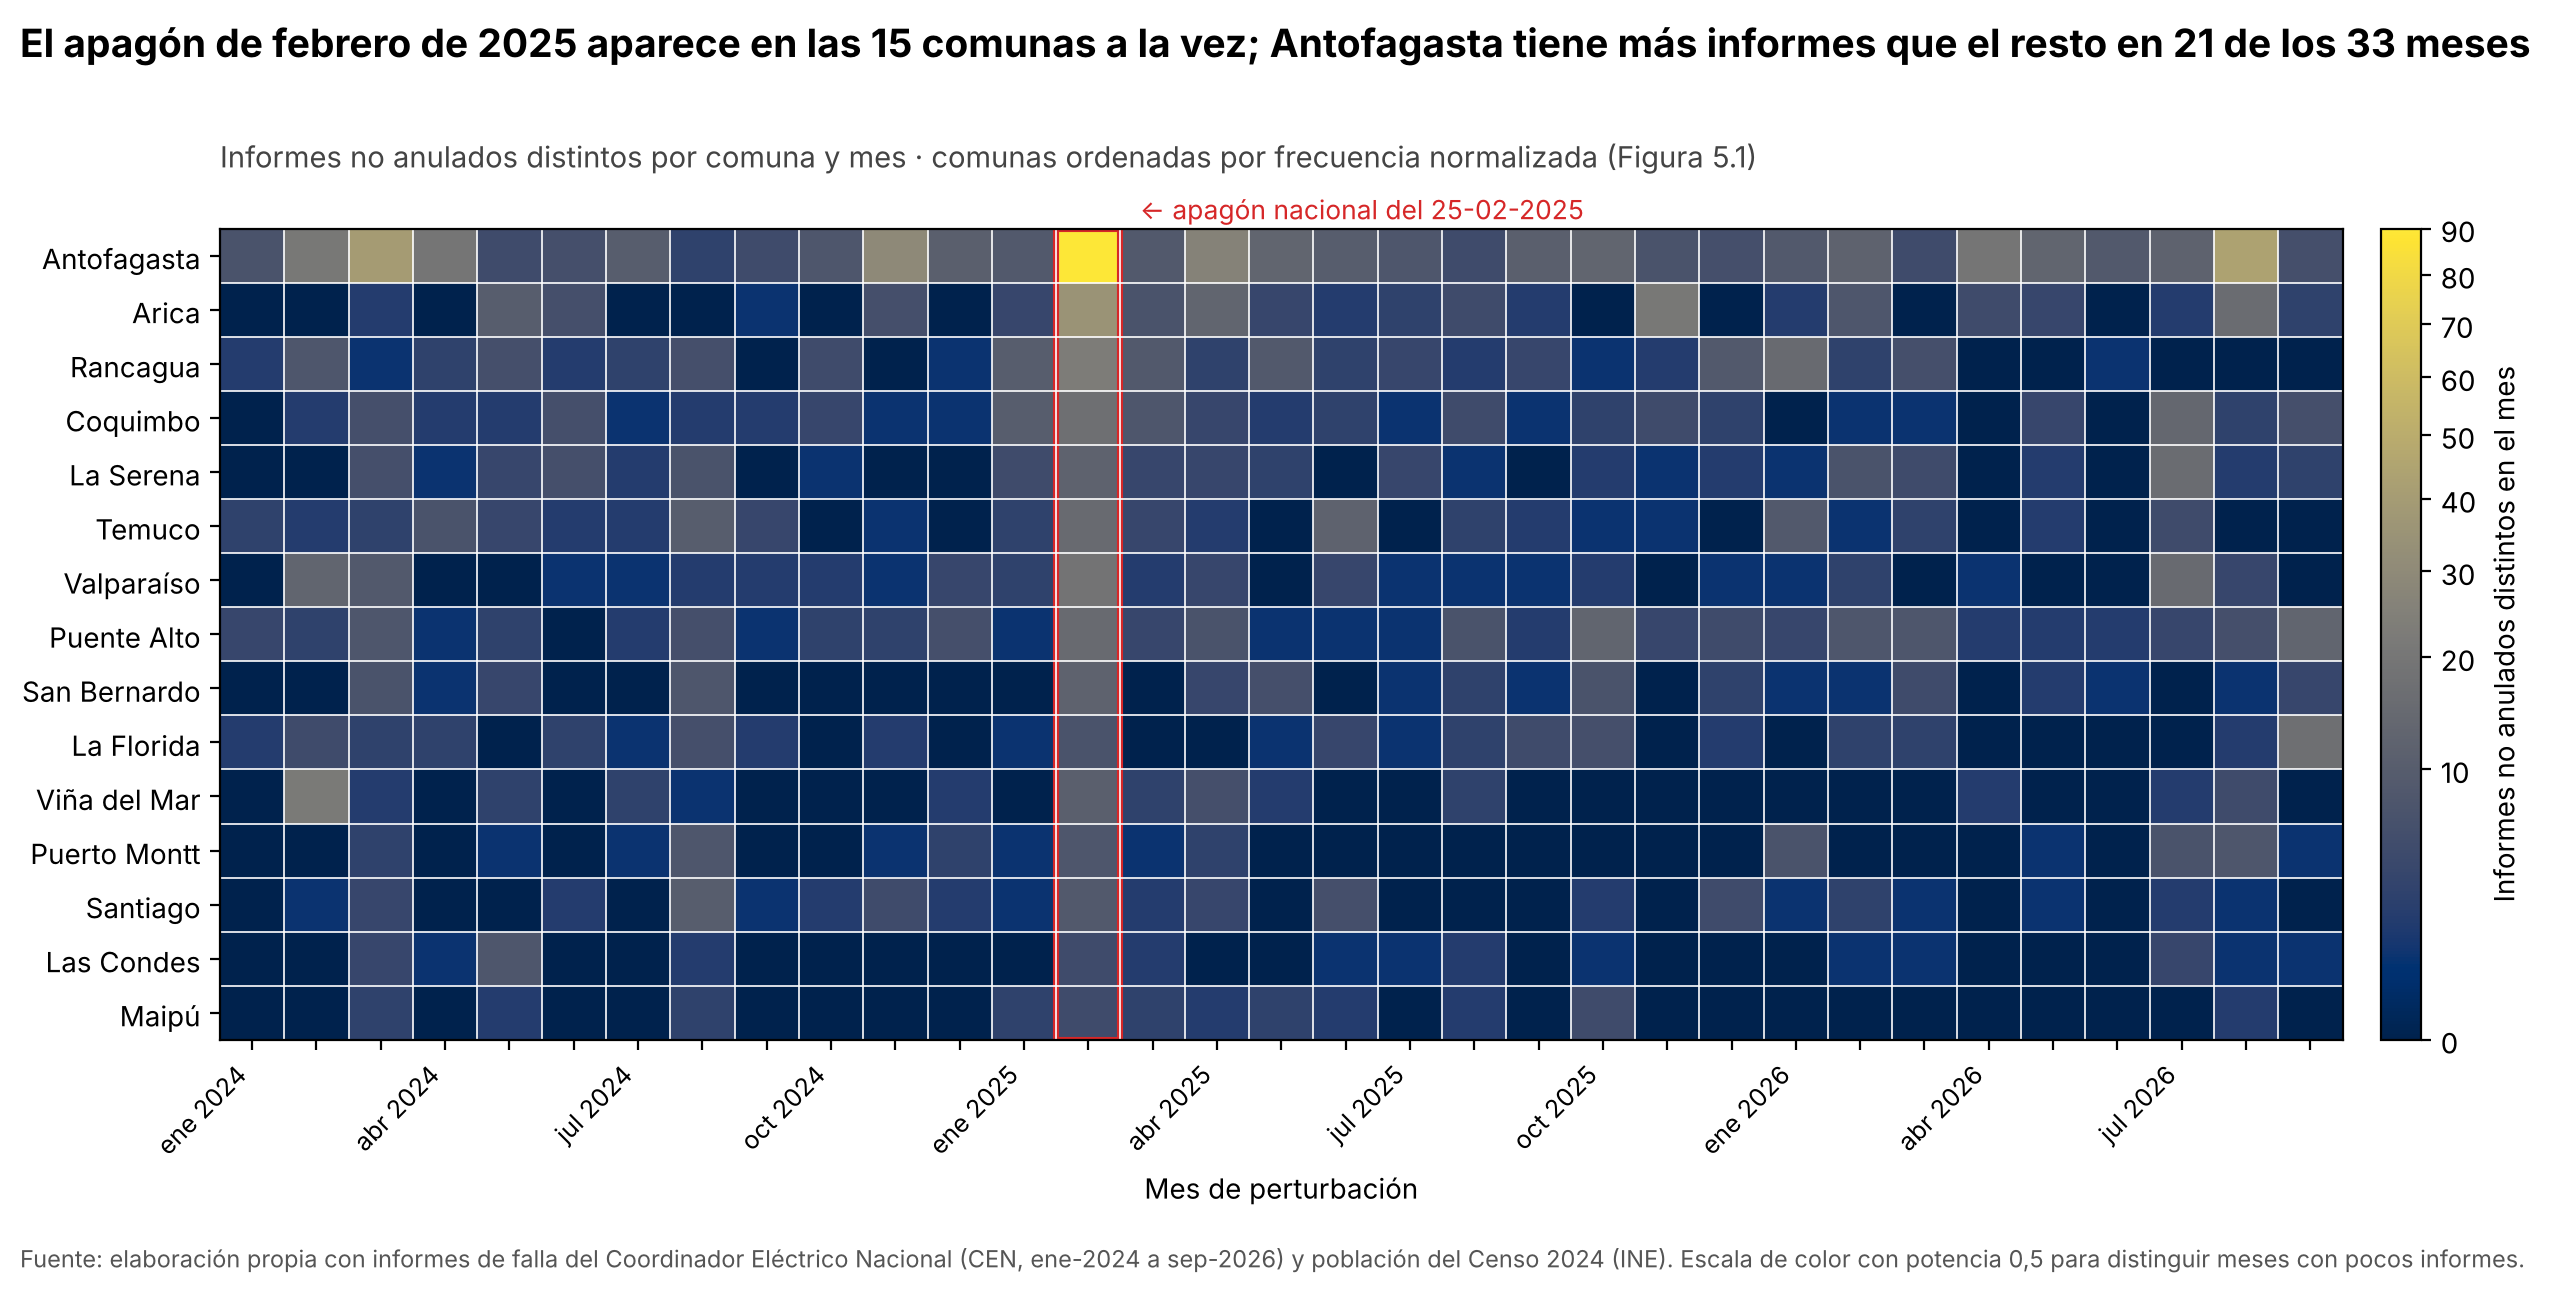

In [3]:
fig = graficar_mapa_calor(
    matriz,
    titulo="El apagón de febrero de 2025 aparece en las 15 comunas a la vez; "
           "Antofagasta tiene más informes que el resto en 21 de los 33 meses",
    subtitulo="Informes no anulados distintos por comuna y mes · comunas ordenadas "
              "por frecuencia normalizada (Figura 5.1)",
    mes_destacado="2025-02",
    ruta_salida=DIR_FIGURAS / "F4_Figura_505_Evolucion_Mensual_Comunal.png",
    fuente=FUENTE + " Escala de color con potencia 0,5 para distinguir meses con pocos informes.",
)
plt.show()

matriz.to_csv(DIR_RESULTADOS / "F4_Tabla_405_Evolucion_Mensual_Comunal.csv",
              encoding="utf-8-sig")

### 2.1. ¿Cuánto pesa el apagón en la frecuencia de cada comuna?

Se recalcula la frecuencia por 100.000 habitantes-año **sin los informes del 25-02-2025** (la misma fecha que excluye el análisis de sensibilidad de F2) y se compara el puesto de cada comuna en el ranking.

In [4]:
peso = peso_de_un_dia(asociaciones, fecha=FECHA_APAGON, panel=panel)
peso.to_csv(DIR_RESULTADOS / "F4_Tabla_406_Peso_Apagon_Comunal.csv",
            index=False, encoding="utf-8-sig")

cambios = peso.loc[peso["puesto_total"] != peso["puesto_sin_dia"], "comuna_oficial"].tolist()
print(f"Informes del 25-02-2025 en las 15 comunas: {peso['informes_del_dia'].sum()}")
print(f"Comuna más afectada: {peso.loc[peso['pct_del_dia'].idxmax(), 'comuna_oficial']} "
      f"({peso['pct_del_dia'].max()} % de sus informes)")
print(f"Comunas que cambian de puesto sin el apagón: {cambios if cambios else 'ninguna'}")
peso

Informes del 25-02-2025 en las 15 comunas: 220
Comuna más afectada: Valparaíso (19.6 % de sus informes)
Comunas que cambian de puesto sin el apagón: ['Viña del Mar', 'Puerto Montt']


,comuna_oficial,informes_total,informes_del_dia,informes_sin_dia,pct_del_dia,frecuencia_total,frecuencia_sin_dia,puesto_total,puesto_sin_dia
0,Antofagasta,503,69,434,13.7,45.60,39.35,1,1
1,Arica,161,22,139,13.7,24.23,20.92,2,2
2,Rancagua,141,19,122,13.5,19.89,17.21,3,3
3,Coquimbo,120,15,105,12.5,16.55,14.48,4,4
4,La Serena,101,9,92,8.9,14.68,13.37,5,5
5,Temuco,101,14,87,13.9,12.56,10.82,6,6
6,Valparaíso,97,19,78,19.6,12.38,9.95,7,7
7,Puente Alto,150,14,136,9.3,9.60,8.71,8,8
8,San Bernardo,72,9,63,12.5,8.55,7.48,9,9
9,La Florida,82,5,77,6.1,7.95,7.47,10,10


### 2.2. Lectura

- **Qué muestra.** Febrero de 2025 suma 283 vínculos informe-comuna no anulados (264 informes distintos), 6,6 veces la mediana de los otros 32 meses (43 vínculos). El pico aparece en las 15 comunas a la vez. Antofagasta es la comuna con más informes en 21 de los 33 meses.
- **Qué se infiere.** El liderazgo de Antofagasta en la Figura 5.1 no depende del apagón: sin los informes del 25-02-2025 su frecuencia baja de 45,60 a 39,35 por 100.000 habitantes-año y sigue primera. El ranking de las 15 comunas casi no cambia: solo Viña del Mar y Puerto Montt intercambian los puestos 11 y 12. Valparaíso es la comuna donde ese día pesa más (19,6 % de sus informes).
- **Qué límite tiene.** Se cuentan informes documentales, no cortes efectivos a clientes. Un mismo informe puede vincularse a varias comunas, por lo que el apagón aparece en varias filas a la vez. La exclusión considera solo el día 25-02-2025; los informes de días cercanos que pudieran estar relacionados se mantienen.
- **Cómo aporta al relato.** Responde la pregunta que dejan abierta las figuras anteriores: los patrones comunales son persistentes en el tiempo y no el efecto de un solo episodio.

## 3. Componente B · Incertidumbre de la frecuencia

Cada tasa se calcula sobre un conteo de informes. El **intervalo exacto de Poisson** del conteo, dividido por la misma población y período de F3, entrega el rango de tasas compatible con los datos al 95 %. Se agrega la referencia del **promedio simple de las 15 tasas** y, con un rombo, la tasa **sin el apagón** (sección 2.1).

In [5]:
frecuencia = frecuencia_con_intervalo(panel, meses_observados=33)

diferencia = (frecuencia.set_index("comuna_oficial")["frecuencia_100k_hab_anio"]
              - panel.set_index("comuna_oficial")["frecuencia_100k_hab_anio"]).abs().max()
assert diferencia == 0, "La frecuencia no coincide con el panel de F3."

frecuencia = frecuencia.merge(peso[["comuna_oficial", "frecuencia_sin_dia"]],
                              on="comuna_oficial", how="left", validate="one_to_one")
promedio = frecuencia["frecuencia_100k_hab_anio"].mean()
no_distinguibles = pares_no_distinguibles(frecuencia)

frecuencia.to_csv(DIR_RESULTADOS / "F4_Tabla_407_Frecuencia_Intervalo_Confianza.csv",
                  index=False, encoding="utf-8-sig")

print(f"Promedio simple de las 15 tasas: {promedio:.2f} por 100.000 hab.-año")
print(f"Pares vecinos en el ranking que NO se distinguen: {len(no_distinguibles)} de 14")
print("Pares vecinos que SÍ se distinguen:",
      [(a, b) for a, b in zip(frecuencia['comuna_oficial'][:-1], frecuencia['comuna_oficial'][1:])
       if (a, b) not in no_distinguibles])
frecuencia

Promedio simple de las 15 tasas: 13.24 por 100.000 hab.-año
Pares vecinos en el ranking que NO se distinguen: 13 de 14
Pares vecinos que SÍ se distinguen: [('Antofagasta', 'Arica')]


,codigo_comuna,comuna_oficial,poblacion_2024,informes_no_anulados,frecuencia_100k_hab_anio,ic_inferior,ic_superior,frecuencia_sin_dia
0,02101,Antofagasta,401096.0,503,45.60,41.70,49.77,39.35
1,15101,Arica,241653.0,161,24.23,20.63,28.27,20.92
2,06101,Rancagua,257744.0,141,19.89,16.74,23.46,17.21
3,04102,Coquimbo,263719.0,120,16.55,13.72,19.79,14.48
4,04101,La Serena,250141.0,101,14.68,11.96,17.84,13.37
5,09101,Temuco,292518.0,101,12.56,10.23,15.26,10.82
6,05101,Valparaíso,284938.0,97,12.38,10.04,15.10,9.95
7,13201,Puente Alto,568086.0,150,9.60,8.13,11.27,8.71
8,13401,San Bernardo,306371.0,72,8.55,6.69,10.76,7.48
9,13110,La Florida,374836.0,82,7.95,6.33,9.87,7.47


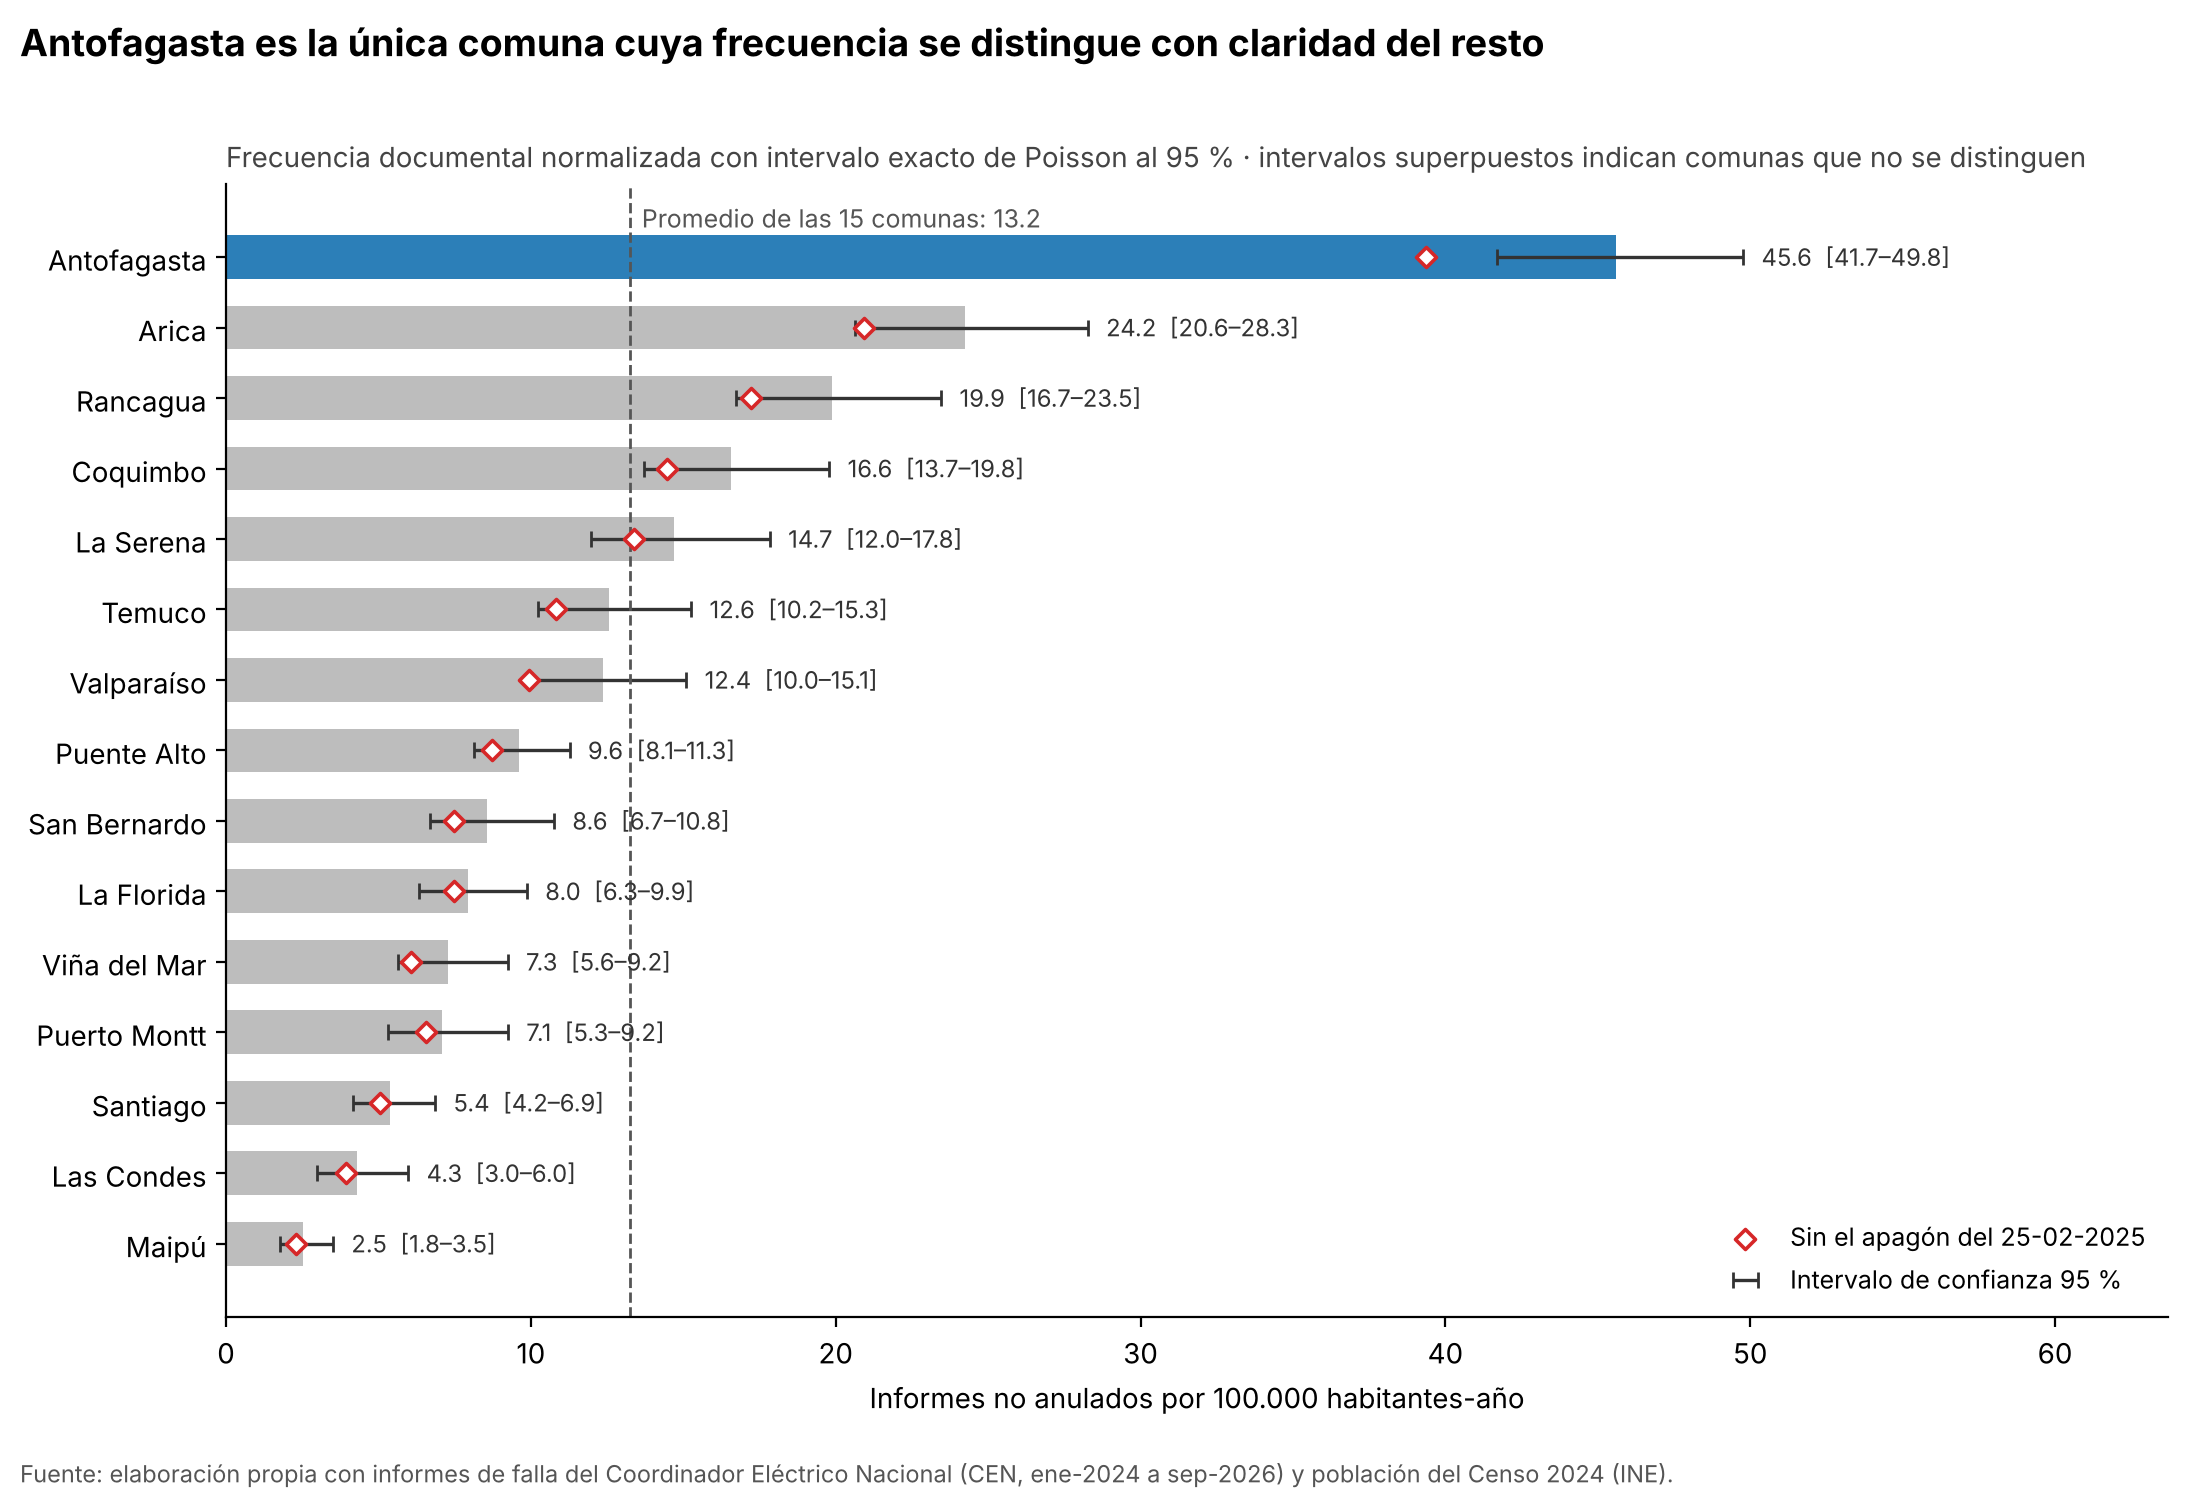

In [6]:
tabla = frecuencia.iloc[::-1].reset_index(drop=True)
posiciones = range(len(tabla))
colores = ["#2c7fb8" if c == "Antofagasta" else "#bdbdbd" for c in tabla["comuna_oficial"]]

fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(posiciones, tabla["frecuencia_100k_hab_anio"], color=colores, height=0.62)
ax.errorbar(tabla["frecuencia_100k_hab_anio"], posiciones,
            xerr=[tabla["frecuencia_100k_hab_anio"] - tabla["ic_inferior"],
                  tabla["ic_superior"] - tabla["frecuencia_100k_hab_anio"]],
            fmt="none", ecolor="#333333", elinewidth=1.2, capsize=3, label="Intervalo de confianza 95 %")
ax.scatter(tabla["frecuencia_sin_dia"], posiciones, marker="D", s=26, facecolor="white",
           edgecolor="#d62728", linewidth=1.3, zorder=3, label="Sin el apagón del 25-02-2025")
ax.axvline(promedio, color="#555555", linestyle="--", linewidth=1)
ax.text(promedio + 0.4, len(tabla) - 0.45, f"Promedio de las 15 comunas: {promedio:.1f}",
        fontsize=9, color="#555555", va="center")

for y, fila in tabla.iterrows():
    ax.text(fila["ic_superior"] + 0.6, y,
            f"{fila['frecuencia_100k_hab_anio']:.1f}  [{fila['ic_inferior']:.1f}–{fila['ic_superior']:.1f}]",
            va="center", fontsize=8.6, color="#333333")

ax.set_yticks(list(posiciones))
ax.set_yticklabels(tabla["comuna_oficial"])
ax.set_xlim(0, tabla["ic_superior"].max() * 1.28)
ax.set_xlabel("Informes no anulados por 100.000 habitantes-año")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.suptitle("Antofagasta es la única comuna cuya frecuencia se distingue con claridad del resto",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
ax.set_title("Frecuencia documental normalizada con intervalo exacto de Poisson al 95 % · "
             "intervalos superpuestos indican comunas que no se distinguen",
             loc="left", fontsize=10, color="#444444")
fig.text(0.01, 0.005, FUENTE, fontsize=8.5, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(DIR_FIGURAS / "F4_Figura_506_Frecuencia_Intervalo_Confianza.png", dpi=200,
            bbox_inches="tight")
plt.show()

### 3.1. Lectura

- **Qué muestra.** El intervalo de Antofagasta (41,7 a 49,8) no se superpone con el de ninguna otra comuna. Arica (20,6 a 28,3) supera a todas las comunas desde Coquimbo hacia abajo, pero no se distingue de Rancagua. Entre las demás comunas vecinas en el ranking, los intervalos se superponen.
- **Qué se infiere.** Lo que el ranking de la Figura 5.1 permite afirmar es que Antofagasta tiene una frecuencia claramente mayor que todas las demás, y que las comunas del extremo alto (por ejemplo, Rancagua, 16,7 a 23,5) superan a las del extremo bajo (por ejemplo, Maipú, 1,8 a 3,5). El orden entre comunas vecinas no es concluyente: La Serena y Temuco (14,7 y 12,6), por ejemplo, no se distinguen.
- **Qué límite tiene.** El intervalo de Poisson supone informes independientes. Un evento que genera varios informes, como el apagón, viola ese supuesto, por lo que los intervalos reales podrían ser algo más anchos. La población es un denominador de contexto, no de clientes eléctricos.
- **Cómo aporta al relato.** Convierte el ranking en una comparación honesta: el informe puede afirmar diferencias solo donde los intervalos no se superponen.

## 4. Componente B · Incertidumbre de la duración

La mediana de los intervalos documentales elegibles (criterio de F3: informe finalizado, intervalo no negativo y fecha de término disponible) se acompaña de un **intervalo bootstrap** (2.000 remuestreos, semilla fija 500) y del percentil 75. Las comunas con menos de 30 intervalos se marcan como **baja precisión**, con el número de intervalos junto a cada comuna.

In [7]:
duracion = duracion_con_intervalo(asociaciones, repeticiones=2000, semilla=500)

control = duracion.set_index("comuna_oficial").join(
    panel.set_index("comuna_oficial")[["informes_validos", "mediana_horas"]], rsuffix="_f3")
assert (control["intervalos_elegibles"] == control["informes_validos"]).all(), \
    "Los intervalos elegibles no coinciden con F3."
assert (control["mediana_horas"] - control["mediana_horas_f3"].round(2)).abs().max() < 0.01

duracion.to_csv(DIR_RESULTADOS / "F4_Tabla_408_Duracion_Intervalo_Confianza.csv",
                index=False, encoding="utf-8-sig")

baja = duracion.loc[duracion["baja_precision"], ["comuna_oficial", "intervalos_elegibles"]]
print(f"Comunas de baja precisión (< {UMBRAL_BAJA_PRECISION} intervalos):")
print(baja.to_string(index=False))
duracion

Comunas de baja precisión (< 30 intervalos):
comuna_oficial  intervalos_elegibles
    Las Condes                     9
  Viña del Mar                    21
         Maipú                    13


,codigo_comuna,comuna_oficial,intervalos_elegibles,mediana_horas,percentil_75_horas,ic_inferior,ic_superior,baja_precision
0,05101,Valparaíso,40,3.47,6.62,1.96,5.87,False
1,13110,La Florida,53,3.07,6.43,2.22,4.78,False
2,13201,Puente Alto,84,2.85,4.85,2.08,3.33,False
3,13101,Santiago,32,2.53,6.14,0.36,4.62,False
4,02101,Antofagasta,307,2.05,5.47,1.60,2.68,False
5,13114,Las Condes,9,2.00,3.92,0.03,8.45,True
6,05109,Viña del Mar,21,1.67,3.03,0.40,2.55,True
7,13119,Maipú,13,1.50,1.78,0.85,1.78,True
8,04102,Coquimbo,77,1.37,6.12,0.73,3.60,False
9,04101,La Serena,41,1.37,4.78,0.53,2.68,False


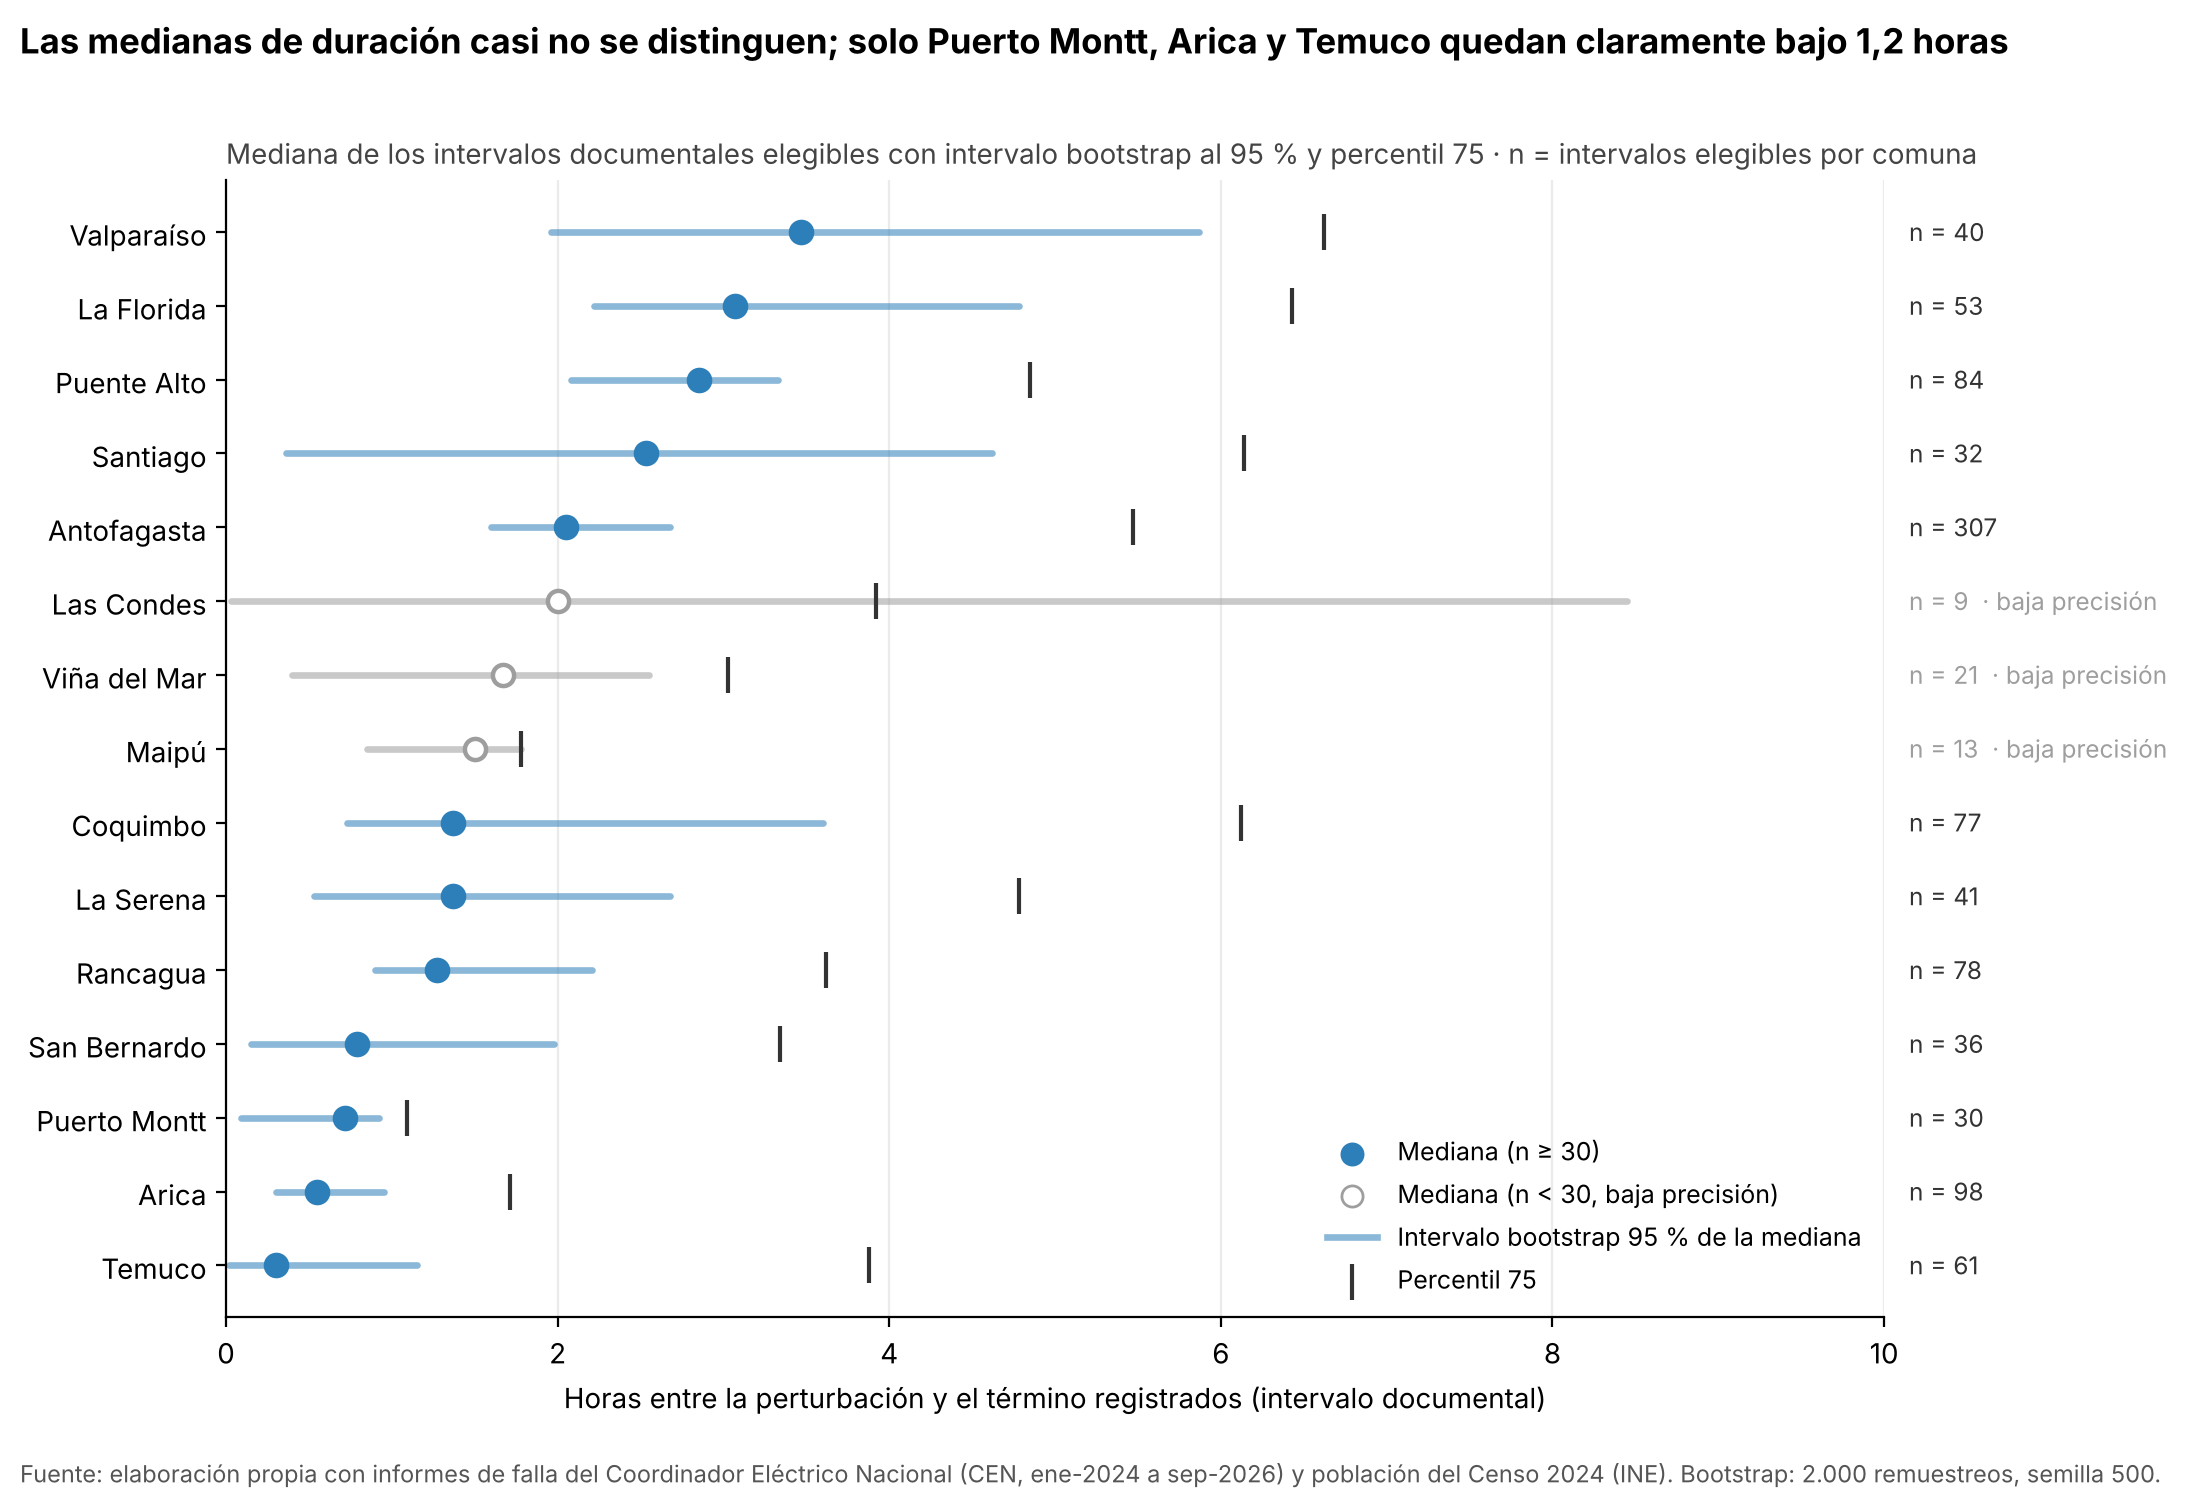

In [8]:
tabla = duracion.iloc[::-1].reset_index(drop=True)
posiciones = list(range(len(tabla)))

fig, ax = plt.subplots(figsize=(11, 7.5))
for y, fila in tabla.iterrows():
    baja_precision = bool(fila["baja_precision"])
    color = "#9e9e9e" if baja_precision else "#2c7fb8"
    ax.plot([fila["ic_inferior"], fila["ic_superior"]], [y, y], color=color,
            linewidth=2.4, alpha=0.55, solid_capstyle="round")
    ax.scatter(fila["mediana_horas"], y, s=58, zorder=3,
               facecolor="white" if baja_precision else color, edgecolor=color, linewidth=1.6)
    ax.scatter(fila["percentil_75_horas"], y, marker="|", s=170, color="#333333", zorder=3)
    etiqueta = f"n = {fila['intervalos_elegibles']}" + ("  · baja precisión" if baja_precision else "")
    ax.text(10.15, y, etiqueta, va="center", fontsize=8.8,
            color="#9e9e9e" if baja_precision else "#333333")

ax.scatter([], [], s=58, facecolor="#2c7fb8", edgecolor="#2c7fb8", label="Mediana (n ≥ 30)")
ax.scatter([], [], s=58, facecolor="white", edgecolor="#9e9e9e", label="Mediana (n < 30, baja precisión)")
ax.plot([], [], color="#2c7fb8", alpha=0.55, linewidth=2.4, label="Intervalo bootstrap 95 % de la mediana")
ax.scatter([], [], marker="|", s=170, color="#333333", label="Percentil 75")

ax.set_yticks(posiciones)
ax.set_yticklabels(tabla["comuna_oficial"])
ax.set_xlim(0, 10)
ax.set_xlabel("Horas entre la perturbación y el término registrados (intervalo documental)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.suptitle("Las medianas de duración casi no se distinguen; solo Puerto Montt, "
             "Arica y Temuco quedan claramente bajo 1,2 horas",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold")
ax.set_title("Mediana de los intervalos documentales elegibles con intervalo bootstrap al 95 % "
             "y percentil 75 · n = intervalos elegibles por comuna",
             loc="left", fontsize=10, color="#444444")
fig.text(0.01, 0.005, FUENTE + " Bootstrap: 2.000 remuestreos, semilla 500.",
         fontsize=8.5, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(DIR_FIGURAS / "F4_Figura_507_Duracion_Intervalo_Confianza.png", dpi=200,
            bbox_inches="tight")
plt.show()

### 4.1. Lectura

- **Qué muestra.** Valparaíso tiene la mediana más alta (3,47 h), pero su intervalo (1,96 a 5,87 h) se superpone con el de casi todas las comunas. Las Condes (n = 9), Maipú (n = 13) y Viña del Mar (n = 21) quedan marcadas como baja precisión; el intervalo de Las Condes va de 0,03 a 8,45 h. Puerto Montt, Arica y Temuco tienen intervalos completamente bajo 1,2 h.
- **Qué se infiere.** La afirmación «Valparaíso tiene la mayor mediana» no se sostiene como diferencia: los datos no permiten distinguirla de La Florida, Puente Alto, Santiago o Antofagasta. Lo que sí se sostiene es que en Puerto Montt, Arica y Temuco los informes se cierran típicamente más rápido que en Valparaíso, La Florida o Puente Alto, cuyos intervalos no se superponen con los de esas tres.
- **Qué límite tiene.** Son tiempos entre hitos documentales, no duraciones de cortes a clientes. Solo se miden los informes finalizados: si los informes más graves quedan pendientes más tiempo, las medianas podrían subestimar la duración real.
- **Cómo aporta al relato.** Completa la Figura 5.3: además de la mediana y el percentil 75, muestra cuánta confianza merece cada cifra y qué comunas no permiten conclusiones.

## 5. Hallazgos para el informe y el video

Cada cifra indica la celda que la produce, como pide la retroalimentación de F3.

| N.º | Hallazgo | Cifra | Celda |
|---|---|---|---|
| H-A1 | Febrero de 2025 concentra los informes del período | 283 vínculos (264 informes distintos), 6,6 veces la mediana mensual del resto (43 vínculos) | §2, celda de la matriz |
| H-A2 | El liderazgo de Antofagasta no depende del apagón | 45,60 → 39,35 por 100.000 hab.-año sin el 25-02-2025; sigue 1.º | §2.1, tabla 406 |
| H-A3 | El ranking de frecuencia es estable frente al apagón | Solo Viña del Mar y Puerto Montt intercambian los puestos 11 y 12 | §2.1, tabla 406 |
| H-B1 | Antofagasta es la única comuna claramente distinta | IC 95 %: 41,7 a 49,8; ninguna otra lo alcanza | §3, tabla 407 |
| H-B2 | Dentro de los grupos intermedio y bajo, el orden no es concluyente | 13 de 14 pares vecinos con intervalos superpuestos | §3, tabla 407 |
| H-B3 | Tres comunas no permiten conclusiones sobre duración | Las Condes (9), Maipú (13), Viña del Mar (21) | §4, tabla 408 |
| H-B4 | La mayor mediana de duración no se distingue del resto | Valparaíso 3,47 h, IC 1,96 a 5,87 h | §4, tabla 408 |

## 6. Verificación final de productos

In [9]:
productos = [
    DIR_FIGURAS / "F4_Figura_505_Evolucion_Mensual_Comunal.png",
    DIR_FIGURAS / "F4_Figura_506_Frecuencia_Intervalo_Confianza.png",
    DIR_FIGURAS / "F4_Figura_507_Duracion_Intervalo_Confianza.png",
    DIR_RESULTADOS / "F4_Tabla_405_Evolucion_Mensual_Comunal.csv",
    DIR_RESULTADOS / "F4_Tabla_406_Peso_Apagon_Comunal.csv",
    DIR_RESULTADOS / "F4_Tabla_407_Frecuencia_Intervalo_Confianza.csv",
    DIR_RESULTADOS / "F4_Tabla_408_Duracion_Intervalo_Confianza.csv",
]
for ruta in productos:
    assert ruta.exists() and ruta.stat().st_size > 0, f"Falta {ruta.name}"
    print(f"[OK] {ruta.relative_to(RAIZ)}")

assert total_mes[mes_pico] == 283 and str(mes_pico) == "2025-02"
assert total_mes.drop(mes_pico).median() == 43
assert frecuencia.loc[0, "comuna_oficial"] == "Antofagasta"
assert not se_superponen(frecuencia.loc[0, "ic_inferior"], frecuencia.loc[0, "ic_superior"],
                         frecuencia.loc[1, "ic_inferior"], frecuencia.loc[1, "ic_superior"])
assert (matriz.idxmax() == "Antofagasta").sum() == 21
assert set(baja["comuna_oficial"]) == {"Las Condes", "Maipú", "Viña del Mar"}
print("[OK] Las cifras citadas en las lecturas coinciden con los cálculos.")

[OK] F4/figuras/F4_Figura_505_Evolucion_Mensual_Comunal.png
[OK] F4/figuras/F4_Figura_506_Frecuencia_Intervalo_Confianza.png
[OK] F4/figuras/F4_Figura_507_Duracion_Intervalo_Confianza.png
[OK] F4/resultados/F4_Tabla_405_Evolucion_Mensual_Comunal.csv
[OK] F4/resultados/F4_Tabla_406_Peso_Apagon_Comunal.csv
[OK] F4/resultados/F4_Tabla_407_Frecuencia_Intervalo_Confianza.csv
[OK] F4/resultados/F4_Tabla_408_Duracion_Intervalo_Confianza.csv
[OK] Las cifras citadas en las lecturas coinciden con los cálculos.
